# Investigation of MUSIN-G Dataset


In [1]:
from pathlib import Path

import braindecode
import mne
import scipy
import sklearn
import skorch
import torch
import torcheeg
import matplotlib

import numpy as np
import pandas as pd
import soundfile as sf

from mne_bids import BIDSPath, find_matching_paths, get_entity_vals, read_raw_bids

In [2]:
DATA_PATH = Path("data")  # directory path of the data files for our computations
SEED = 42  # random seed for reproducibility

## Load Data

In [3]:
SONG_NAMES = {
    1: "Trip to the lonely planet",
    2: "Sail",
    3: "Concept 15",
    4: "Aurore",
    5: "Proof",
    6: "Glider",
    7: "Raag Bihag",
    8: "Albela sajan",
    9: "Mor Bani thanghat Kare",
    10: "Fallin",
    11: "Master of Running",
    12: "JB",
}

montage = mne.channels.make_standard_montage("GSN-HydroCel-129")

def LoadMUSIN_G(
    filepath: Path = DATA_PATH / "ds003774-download",
    subject_slice: slice = slice(0,20),
    sfreq: int = 125,
) -> pd.DataFrame:
    """
    Load data from https://openneuro.org/datasets/ds003774/versions/1.0.2

    Returns one row per recording (one song for one participant), with columns:
        subject, session, run, song_num, song_name, sfreq, n_times, duration_s,
        wav_path, bids_path, raw

    Note:
        - for 11 participants, the sampling rate of EEG is 1000Hz, for the remaining 9, 250Hz.
            - resample all to 125 Hz by default
        - the 1st session corresponds to song 1 (the README says each session is a song number).
        - `subject_slice` picks which participants to load.
    """
    subjects = get_entity_vals(filepath, "subject")[subject_slice]
    sessions = get_entity_vals(filepath, "session")
    task = get_entity_vals(filepath, "task")[0]
    
    rows = []
    for sub in subjects:
        print("Subject: " + sub)
        for ses in sessions:
            print("Session: " + ses)
            paths = find_matching_paths(
                subjects=sub,
                sessions=ses,
                tasks=task,
                extensions=[".set"],
                suffixes="eeg",
                root=filepath,
            )
            song_num = int(ses)
            song_file = filepath / "Code" / "ESongs" / f"{song_num}.esh.wav"

            for path in paths:
                raw = read_raw_bids(path)
                raw.resample(sfreq = sfreq)
                
                # Provided data names the 'Cz" electrode, "E129"
                raw.rename_channels({'E129': 'Cz'})
                raw.set_montage(montage)
    
                audio, audio_rate = sf.read(song_file)
                
                raw.load_data()
    
                rows.append(
                    {
                        "subject": sub,
                        "session": ses,
                        "run": path.run,
                        "song_num": song_num,
                        "song_name": SONG_NAMES[song_num],
                        "wav_path": song_file,
                        # "audio": audio,
                        "audio_rate": audio_rate,
                        "bids_path": path,
                        "raw": raw,
                    }
                )

    return pd.DataFrame(rows)

In [4]:
df = LoadMUSIN_G()

Subject: 001
Session: 01
Session: 02
Session: 03
Session: 04
Session: 05
Session: 06
Session: 07
Session: 08
Session: 09
Session: 10
Session: 11
Session: 12
Subject: 002
Session: 01
Session: 02
Session: 03
Session: 04
Session: 05
Session: 06
Session: 07
Session: 08
Session: 09
Session: 10
Session: 11
Session: 12
Subject: 003
Session: 01
Session: 02
Session: 03
Session: 04
Session: 05
Session: 06
Session: 07
Session: 08
Session: 09
Session: 10
Session: 11
Session: 12
Subject: 004
Session: 01
Session: 02
Session: 03
Session: 04
Session: 05
Session: 06
Session: 07
Session: 08
Session: 09
Session: 10
Session: 11
Session: 12
Subject: 005
Session: 01
Session: 02
Session: 03
Session: 04
Session: 05
Session: 06
Session: 07
Session: 08
Session: 09
Session: 10
Session: 11
Session: 12
Subject: 006
Session: 01
Session: 02
Session: 03
Session: 04
Session: 05
Session: 06
Session: 07
Session: 08
Session: 09
Session: 10
Session: 11
Session: 12
Subject: 007
Session: 01
Session: 02
Session: 03
Session: 

In [5]:
df

,subject,session,run,song_num,song_name,wav_path,audio_rate,bids_path,raw
0,001,01,1,1,Trip to the lonely planet,data/ds003774-download/Code/ESongs/1.esh.wav,8000,data/ds003774-download/sub-001/ses-01/eeg/sub-...,<RawEEGLAB | sub-001_ses-01_task-MusicListenin...
1,001,02,2,2,Sail,data/ds003774-download/Code/ESongs/2.esh.wav,8000,data/ds003774-download/sub-001/ses-02/eeg/sub-...,<RawEEGLAB | sub-001_ses-02_task-MusicListenin...
2,001,03,3,3,Concept 15,data/ds003774-download/Code/ESongs/3.esh.wav,8000,data/ds003774-download/sub-001/ses-03/eeg/sub-...,<RawEEGLAB | sub-001_ses-03_task-MusicListenin...
3,001,04,4,4,Aurore,data/ds003774-download/Code/ESongs/4.esh.wav,8000,data/ds003774-download/sub-001/ses-04/eeg/sub-...,<RawEEGLAB | sub-001_ses-04_task-MusicListenin...
4,001,05,5,5,Proof,data/ds003774-download/Code/ESongs/5.esh.wav,8000,data/ds003774-download/sub-001/ses-05/eeg/sub-...,<RawEEGLAB | sub-001_ses-05_task-MusicListenin...
...,...,...,...,...,...,...,...,...,...
235,020,08,8,8,Albela sajan,data/ds003774-download/Code/ESongs/8.esh.wav,8000,data/ds003774-download/sub-020/ses-08/eeg/sub-...,<RawEEGLAB | sub-020_ses-08_task-MusicListenin...
236,020,09,9,9,Mor Bani thanghat Kare,data/ds003774-download/Code/ESongs/9.esh.wav,8000,data/ds003774-download/sub-020/ses-09/eeg/sub-...,<RawEEGLAB | sub-020_ses-09_task-MusicListenin...
237,020,10,10,10,Fallin,data/ds003774-download/Code/ESongs/10.esh.wav,8000,data/ds003774-download/sub-020/ses-10/eeg/sub-...,<RawEEGLAB | sub-020_ses-10_task-MusicListenin...
238,020,11,11,11,Master of Running,data/ds003774-download/Code/ESongs/11.esh.wav,8000,data/ds003774-download/sub-020/ses-11/eeg/sub-...,<RawEEGLAB | sub-020_ses-11_task-MusicListenin...


In [6]:
df.memory_usage()

Index          132
subject       1920
session       1920
run           1920
song_num      1920
song_name     1920
wav_path      1920
audio_rate    1920
bids_path     1920
raw           1920
dtype: int64

## Preprocess data


In [8]:
# Cz is the reference electrode, the data was already referenced to Cz and is flat
# Exclude it from model inputs
df["raw"].apply(lambda x: x.drop_channels("Cz") if "Cz" in x.ch_names else x)

# Cut the 10s of silence from the raw recording
df["raw"].apply(lambda x: x.crop(tmin=10.0))


0      <RawEEGLAB | sub-001_ses-01_task-MusicListenin...
1      <RawEEGLAB | sub-001_ses-02_task-MusicListenin...
2      <RawEEGLAB | sub-001_ses-03_task-MusicListenin...
3      <RawEEGLAB | sub-001_ses-04_task-MusicListenin...
4      <RawEEGLAB | sub-001_ses-05_task-MusicListenin...
                             ...                        
235    <RawEEGLAB | sub-020_ses-08_task-MusicListenin...
236    <RawEEGLAB | sub-020_ses-09_task-MusicListenin...
237    <RawEEGLAB | sub-020_ses-10_task-MusicListenin...
238    <RawEEGLAB | sub-020_ses-11_task-MusicListenin...
239    <RawEEGLAB | sub-020_ses-12_task-MusicListenin...
Name: raw, Length: 240, dtype: object

In [64]:
# Filter the data
df["raw"].apply(lambda x: x.filter(0.1, 60))

0      <RawEEGLAB | sub-001_ses-01_task-MusicListenin...
1      <RawEEGLAB | sub-001_ses-02_task-MusicListenin...
2      <RawEEGLAB | sub-001_ses-03_task-MusicListenin...
3      <RawEEGLAB | sub-001_ses-04_task-MusicListenin...
4      <RawEEGLAB | sub-001_ses-05_task-MusicListenin...
                             ...                        
235    <RawEEGLAB | sub-020_ses-08_task-MusicListenin...
236    <RawEEGLAB | sub-020_ses-09_task-MusicListenin...
237    <RawEEGLAB | sub-020_ses-10_task-MusicListenin...
238    <RawEEGLAB | sub-020_ses-11_task-MusicListenin...
239    <RawEEGLAB | sub-020_ses-12_task-MusicListenin...
Name: raw, Length: 240, dtype: object

## Classify the song based on EEG

In [9]:
from sklearn.model_selection import GroupShuffleSplit

epoch, song, subject = [], [], []
for index, row in df.iterrows():
    print("Index:", index)
    ep = mne.make_fixed_length_epochs(
        row["raw"].copy(), duration=2, overlap=1
    )
    epoch.append(ep.get_data())
    song.append([row["song_name"]] * len(ep))
    subject.append([row["subject"]] * len(ep))
    
epoch = np.concatenate(epoch)
song = np.concatenate(song)
subject = np.concatenate(subject)


Index: 0
Index: 1
Index: 2
Index: 3
Index: 4
Index: 5
Index: 6
Index: 7
Index: 8
Index: 9
Index: 10
Index: 11
Index: 12
Index: 13
Index: 14
Index: 15
Index: 16
Index: 17
Index: 18
Index: 19
Index: 20
Index: 21
Index: 22
Index: 23
Index: 24
Index: 25
Index: 26
Index: 27
Index: 28
Index: 29
Index: 30
Index: 31
Index: 32
Index: 33
Index: 34
Index: 35
Index: 36
Index: 37
Index: 38
Index: 39
Index: 40
Index: 41
Index: 42
Index: 43
Index: 44
Index: 45
Index: 46
Index: 47
Index: 48
Index: 49
Index: 50
Index: 51
Index: 52
Index: 53
Index: 54
Index: 55
Index: 56
Index: 57
Index: 58
Index: 59
Index: 60
Index: 61
Index: 62
Index: 63
Index: 64
Index: 65
Index: 66
Index: 67
Index: 68
Index: 69
Index: 70
Index: 71
Index: 72
Index: 73
Index: 74
Index: 75
Index: 76
Index: 77
Index: 78
Index: 79
Index: 80
Index: 81
Index: 82
Index: 83
Index: 84
Index: 85
Index: 86
Index: 87
Index: 88
Index: 89
Index: 90
Index: 91
Index: 92
Index: 93
Index: 94
Index: 95
Index: 96
Index: 97
Index: 98
Index: 99
Index: 100

In [10]:
# Train test split
gss = GroupShuffleSplit(n_splits=1, test_size=2, random_state=SEED)
train_idx, test_idx = next(gss.split(epoch, song, groups=subject))

Xtrain, Xtest = epoch[train_idx], epoch[test_idx]
ytrain, ytest = song[train_idx], song[test_idx]
subject_train = subject[train_idx]

# Train validation split
# train_idx, valid_idx = next(gss.split(Xtrain, ytrain, groups=subject_train))
# Xtrain, Xvalid = Xtrain[train_idx], Xtrain[valid_idx]
# ytrain, yvalid = ytrain[train_idx], ytrain[valid_idx]

## Train the Model

In [11]:
from braindecode.models import EEGNet, 
from braindecode.datautil import infer_signal_properties

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
le.fit(song)
y_enc = le.transform(song)

ytrain_enc = le.transform(ytrain)
ytest_enc = le.transform(ytest)
# yvalid_enc = le.transform(yvalid)

sig_props = infer_signal_properties(epoch, song, mode="classification")

eegnet_model = EEGNet(
    n_chans=sig_props["n_chans"],
    n_outputs=sig_props["n_outputs"],
    n_times=sig_props["n_times"],
    final_conv_length="auto",
    F1=8,
    D=2,
)



In [13]:
from braindecode import EEGClassifier
from skorch.helper import predefined_split
from skorch.dataset import ValidSplit, Dataset
from skorch.callbacks import LRScheduler

cuda = torch.cuda.is_available()
device = "cuda" if cuda else "cpu"
if cuda:
    torch.backends.cudnn.benchmark = True

max_epochs = 60
batch_size = 64

lr = 0.001
weight_decay = 0

clf = EEGClassifier(
    eegnet_model,
    criterion=torch.nn.CrossEntropyLoss,
    optimizer=torch.optim.AdamW,
    # train_split=predefined_split(Dataset(Xvalid, yvalid_enc)),
    train_split=ValidSplit(0.2, random_state=SEED),
    optimizer__lr=lr,
    optimizer__weight_decay=weight_decay,
    batch_size=batch_size,
    max_epochs=max_epochs,
        callbacks=[
        (
            "lr_scheduler",
            LRScheduler(
                "CosineAnnealingLR", monitor="valid_loss", T_max=max_epochs-1
            ),
        ),
    ],
    device=device,
    classes=[SONG_NAMES[i] for i in range(1, 13)]
)


In [14]:
clf.fit(Xtrain, ytrain_enc)

  epoch    train_accuracy    train_loss    valid_acc    valid_accuracy    valid_loss      lr       dur
-------  ----------------  ------------  -----------  ----------------  ------------  ------  --------
      1            0.1042        2.3848       0.1149            0.1149        2.4531  0.0010  128.5959
      2            0.3278        2.0145       0.3359            0.3359        1.8814  0.0010  126.8993
      3            0.4378        1.7155       0.4369            0.4369        1.5002  0.0010  126.6427
      4            0.4840        1.5206       0.4828            0.4828        1.3976  0.0010  126.0107
      5            0.5311        1.3832       0.5310            0.5310        1.2630  0.0010  122.3534
      6            0.5670        1.2881       0.5643            0.5643        1.1155  0.0010  121.4491
      7            0.5915        1.2044       0.5984            0.5984        1.0879  0.0010  119.8358
      8            0.6229        1.1382       0.6225            0.6225   

,module,EEGNet( (en...') ) ) )
,callbacks,"['accuracy', ('lr_scheduler', ...)]"
,optimizer,<class 'torch....adamw.AdamW'>
,lr,0.01
,max_epochs,60
,batch_size,64
,iterator_train,<class 'torch...r.DataLoader'>
,iterator_valid,<class 'torch...r.DataLoader'>
,dataset,<class 'skorc...aset.Dataset'>
,train_split,<skorch.datas...x7f2872346ea0>
,predict_nonlinearity,'auto'


In [19]:
from braindecode.visualization import plot_confusion_matrix
from sklearn.metrics import confusion_matrix, accuracy_score

score = accuracy_score(ytest_enc, clf.predict(Xtest))
print("Score:", score)

score = accuracy_score(ytrain_enc, clf.predict(Xtrain))
print("Score:", score)

Score: 0.11891319689484828
Score: 0.7568023210225046


In [57]:
from matplotlib import pyplot as plt

def plot_loss_curve(classifiers, labels=None):
    """
    Plot train and validation loss curves for one or more classifiers.

    Parameters
    ----------
    classifiers : list
        List of fitted classifiers with a skorch/braindecode-style `history`.
    labels : list[str], optional
        Names to use for each classifier in the legend.

    Returns
    -------
    fig : matplotlib.figure.Figure
        The generated matplotlib figure.
    """

    if not isinstance(classifiers, (list, tuple)):
        classifiers = [classifiers]

    if labels is None:
        labels = [f"Classifier {i + 1}" for i in range(len(classifiers))]

    if len(labels) != len(classifiers):
        raise ValueError("`labels` must have the same length as `classifiers`.")

    fig, ax = plt.subplots(figsize=(8, 5))

    results_columns = ["train_loss", "valid_loss"]

    for clf, label in zip(classifiers, labels):
        _df = pd.DataFrame(
            clf.history[:, results_columns],
            columns=results_columns,
            index=clf.history[:len(clf.history[:, results_columns]), "epoch"],
        )

        ax.plot(
            _df.index,
            _df["train_loss"],
            linestyle="-",
            label=f"{label} train loss",
        )

        ax.plot(
            _df.index,
            _df["valid_loss"],
            linestyle="--",
            label=f"{label} valid loss",
        )

    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(True, alpha=0.3)

    fig.tight_layout()

    return fig

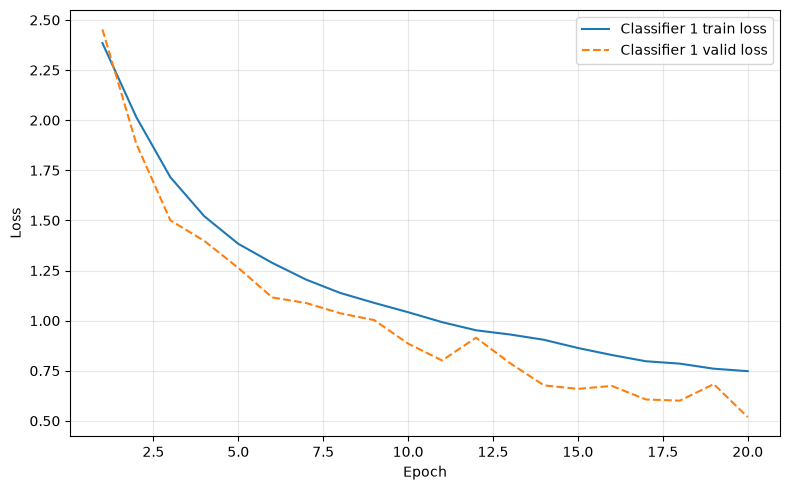

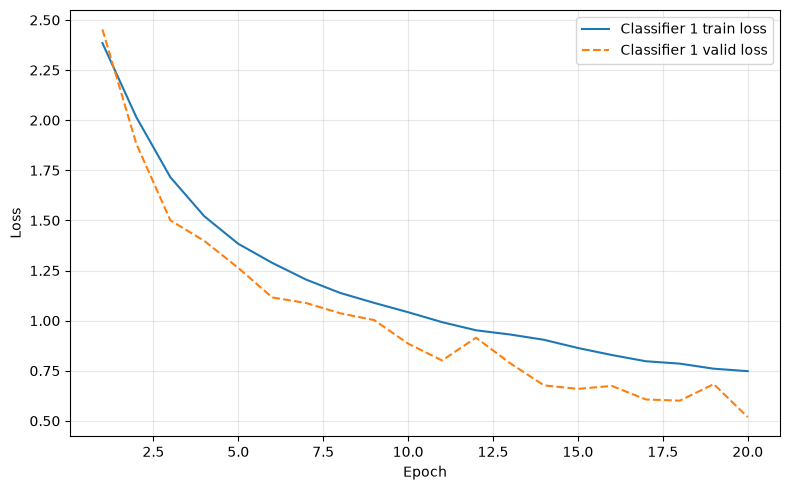

In [58]:
plot_loss_curve(clf)

In [61]:
torch.save(eegnet_model.state_dict(), "eegnet.pt")